In [3]:
%load_ext autoreload
%autoreload 2

In [1]:
import sys
import os

sys.path.append("../..")

import json
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import dask
from dask.diagnostics import ProgressBar
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import rioxarray as rxr
import seaborn as sns
import xarray as xr
from src.data_processing.load_data import ClimateModelData
from src.data_processing.test_climate_data import (
    has_duplicate_coords,
    has_identical_random_timesteps,
    is_time_sorted,
)
from src.utils.cdo_commands import cdo_remap, save_cdo_griddes
from src.utils.constants import EXTENT_BC, EXTENT_BC_MRRO, EXTENT_CH, REFERENCE_PERIOD, FUTURE_PERIOD, EXTENT_PREVAH, REGRIDDED_CHUNKS, BC_DAILY_CHUNKS, BC_SUBDAILY_CHUNKS
from src.utils.utils_xarray import sel_extent

In [2]:
paths = json.load(open("../../paths_so4.json"))
path_data_processed = Path(paths["path_data_processed"])
path_data_temporary = Path(paths["path_data_temporary"])

In [4]:
dask.config.set(num_workers=10)
dask.config.set({"array.chunk-size": "500MiB"})


os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

dask.config.set({"logging.distributed": "error"})
dask.config.set(num_workers=16, threads_per_worker=16)
dask.config.set({"array.chunk-size": "400MiB"})

dask.config.set({'distributed.worker.memory.target': 0.75})  # Spill to disk at 75% usage
dask.config.set({'distributed.worker.memory.spill': 0.8})   # Start spilling at 80%
dask.config.set({'distributed.worker.memory.pause': 0.9})   # Pause worker at 90%

In [14]:
paths_file = "../../paths_so4.json"
climate_model_chain = "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1"
climate_scenario = "rcp26"

path_data_processed = Path(paths["path_data_processed"])
path_data_temporary = Path(paths["path_data_temporary"])

climate_data_dir = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
)

tmp_climate_data_dir = (
    path_data_temporary
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
)

temp_res = "day"
variable = "mrro"

# Load the regridded and bias-corrected datasets
ds_regridded = ClimateModelData(
    climate_data_dir / "regridded" / temp_res / f"{variable}.zarr",
    extent=EXTENT_BC_MRRO,
    chunks=REGRIDDED_CHUNKS
)

ds_bc = ClimateModelData(
    climate_data_dir / "bias_corrected" / temp_res / f"{variable}.zarr",
    extent=EXTENT_BC_MRRO,
    chunks=BC_DAILY_CHUNKS
)

# convert from kg m-2 to kg m-2 s-1
ds_bc.ds_data = ds_bc.ds_data / 86400
ds_bc.ds_data["mrro"].attrs["units"] = "kg m-2 s-1"
# Apply the mask to the bias-corrected dataset
# to set NaNs present in the dataset prior to bias correction back to NaN
print("Applying mask to bias-corrected dataset...")
with ProgressBar(dt=1):
    mask_nan = ds_regridded.ds_data[variable].sel(time="1991-01-01").isnull().compute()
    mask_nan = mask_nan.drop_vars("time").squeeze()
    ds_bc.ds_data = ds_bc.ds_data.where(~mask_nan)

temp_output_dir = tmp_climate_data_dir / "temp" / "mrro" / "blocks"
temp_output_dir.mkdir(parents=True, exist_ok=True)

Applying mask to bias-corrected dataset...
[########################################] | 100% Completed | 23.27 s


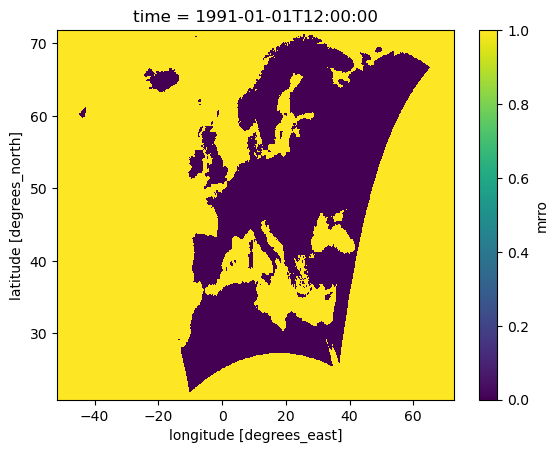

In [19]:
mask_nan.plot()

In [15]:
ds_bc.ds_data

<xarray.Dataset> Size: 202GB
Dimensions:  (time: 39783, lat: 510, lon: 1245)
Coordinates:
  * lat      (lat) float64 4kB 20.9 21.0 21.1 21.2 21.3 ... 71.5 71.6 71.7 71.8
    lev      float64 8B ...
  * lon      (lon) float64 10kB -51.7 -51.6 -51.5 -51.4 ... 72.4 72.5 72.6 72.7
  * time     (time) datetime64[ns] 318kB 1991-01-01T12:00:00 ... 2099-12-29T1...
Data variables:
    mrro     (time, lat, lon) float64 202GB dask.array<chunksize=(365, 256, 256), meta=np.ndarray>
Attributes: (12/27)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Conventions:                    CF-1.4
    NCO:                            4.7.3
    bias_adjustment:                EmpiricalQuantileMapping(group=Grouper(na...
    ...                             ...
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v1
    reference_period:               1991 - 2020
    references:                     https://www.metoffice.gov.uk/climate-guid...
    tracking_id:                    hdl:21.14103/3936c22a-5fbd-49b0-9749-8788...

In [ ]:
for file in temp_output_dir.glob("*.nc"):
    file.unlink()

In [10]:
print("Writing and regridding masked dataset in 20-year blocks...")
first_year = ds_bc.ds_data["time"].dt.year.min().item()
last_year = ds_bc.ds_data["time"].dt.year.max().item()
last_year = 2000

for year_start in range(first_year, last_year + 1, 30):
    year_end = min(year_start + 19, last_year)
    block_file = temp_output_dir / f"{variable}_masked_{year_start}_{year_end}.nc"
    block_file_regridded = temp_output_dir / f"{variable}_masked_regridded_{year_start}_{year_end}.nc"
    if not block_file.exists() and not block_file_regridded.exists():
        print(f"\tProcessing years {year_start}-{year_end}...")
        ds_block = ds_bc.ds_data.sel(
            time=slice(f"{year_start}-01-01", f"{year_end}-12-31")
        )
        with ProgressBar(dt=1):
            ds_block.to_netcdf(block_file)

        cdo_remap(
            str(block_file),
            str(block_file_regridded),
            "conservative",
            path_data_processed / "climate_grids" / "g010_MERIT_2.txt"
        )
        # block_file.unlink()

Writing and regridding masked dataset in 20-year blocks...
	Processing years 1991-2000...
[########################################] | 100% Completed | 50.05 s


cdi  warning (cdfScanVarAttr): NetCDF: Variable not found - time_bnds
cdi  warning (cdfInqContents): Coordinates variable lev can't be assigned!


cdo    remapcon: YAC first order conservative weights from lonlat (1245x510) to lonlat (3600x1400) grid, with source mask (0)


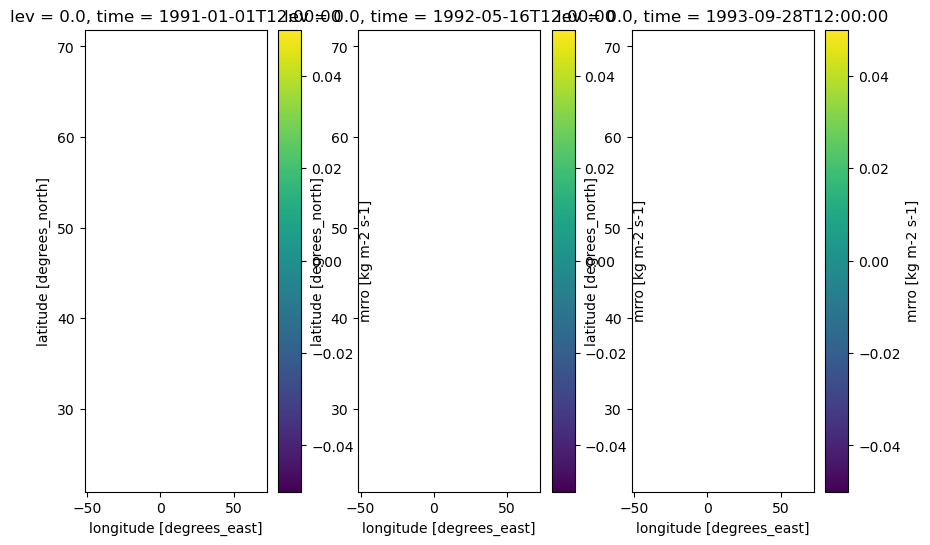

In [12]:
ds_test = xr.open_dataset(tmp_climate_data_dir / "temp" / "mrro" / "blocks" / "mrro_masked_1991_2000.nc")
fig, ax = plt.subplots(1, 3, figsize=(10, 6))
for i, t_index in enumerate([0, 500, 1000]):
    ds_test.isel(time=t_index).mrro.plot(ax=ax[i])
plt.show()

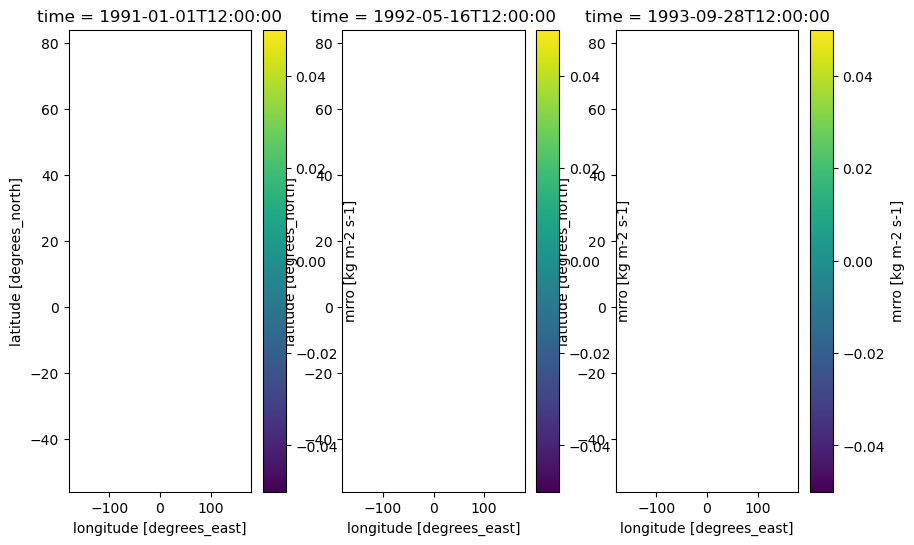

In [11]:
ds_test = xr.open_dataset(tmp_climate_data_dir / "temp" / "mrro" / "blocks" / "mrro_masked_regridded_1991_2000.nc")
fig, ax = plt.subplots(1, 3, figsize=(10, 6))
for i, t_index in enumerate([0, 500, 1000]):
    ds_test.isel(time=t_index).mrro.plot(ax=ax[i])
plt.show()

# Test

In [ ]:
print("Writing masked dataset in 20-year blocks...")
start = pd.Timestamp(ds_bc.ds_data["time"].values[0]).strftime('%Y')
end = pd.Timestamp(ds_bc.ds_data["time"].values[-1]).strftime('%Y')

block_file = temp_output_dir / f"{variable}_masked_{start}_{end}.nc"
block_file_regridded = temp_output_dir / f"{variable}_masked_regridded_{start}_{end}.nc"
if not block_file.exists() and not block_file_regridded.exists():
    with ProgressBar(dt=1):
        ds_bc.ds_data.to_netcdf(block_file)

Writing masked dataset in 20-year blocks...
[########################################] | 100% Completed | 111.21 s


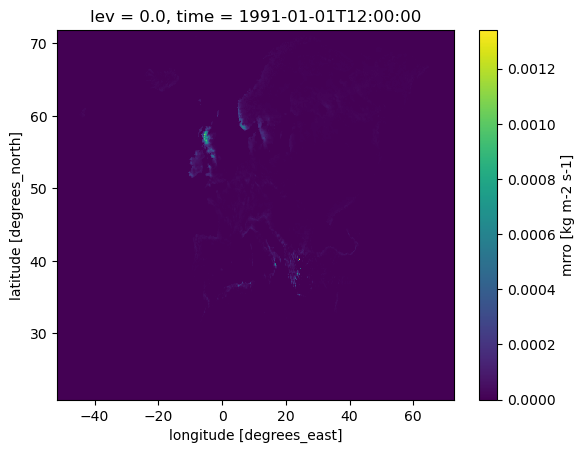

In [13]:
ds_bc = ClimateModelData(
    climate_data_dir / "bias_corrected" / temp_res / f"{variable}.zarr",
    extent=EXTENT_BC_MRRO,
    chunks=BC_DAILY_CHUNKS
)
ds_bc.ds_data = ds_bc.ds_data.sel(time=slice("1991-01-01", "1991-02-01"))
ds_bc.ds_data = ds_bc.ds_data / 86400
ds_bc.ds_data["mrro"].attrs["units"] = "kg m-2 s-1"
ds_bc.ds_data.isel(time=0).mrro.plot()

In [18]:
with ProgressBar(dt=1):
    mask_nan = mask_nan.compute()

[########################################] | 100% Completed | 29m 21s


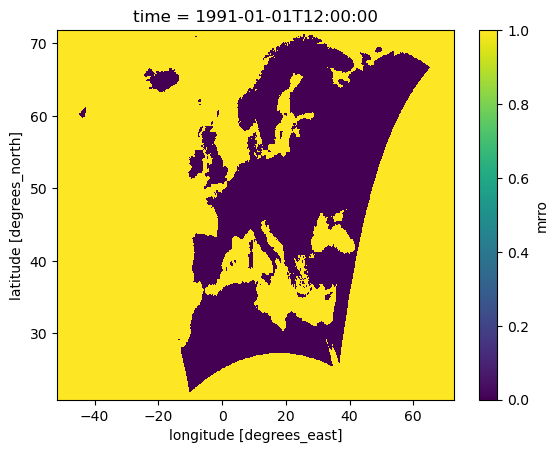

In [19]:
mask_nan.plot()

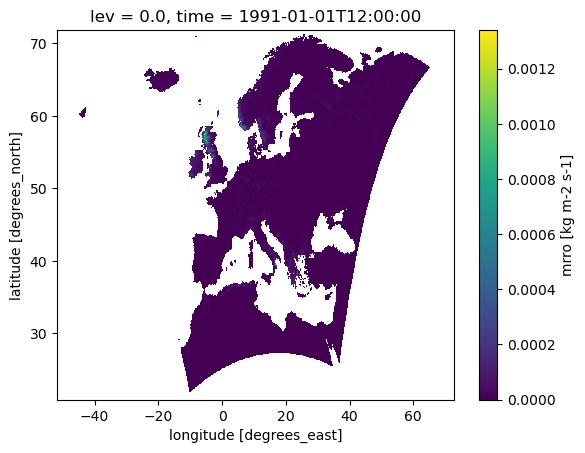

In [11]:
ds_masked = xr.open_dataset(block_file)
ds_masked.isel(time=0).mrro.plot()

In [7]:
if not block_file_regridded.exists() and block_file.exists():
    cdo_remap(
        str(block_file),
        str(block_file_regridded),
        "conservative",
        path_data_processed / "climate_grids" / "g010_MERIT_2.txt"
    )
    # block_file.unlink()

cdi  warning (cdfScanVarAttr): NetCDF: Variable not found - time_bnds
cdi  warning (cdfInqContents): Coordinates variable lev can't be assigned!


cdo    remapcon: YAC first order conservative weights from lonlat (1245x510) to lonlat (3600x1400) grid, with source mask (179887)
cdo    remapcon: YAC first order conservative weights from lonlat (1245x510) to lonlat (3600x1400) grid, with source mask (179886)
cdo    remapcon: YAC first order conservative weights from lonlat (1245x510) to lonlat (3600x1400) grid, with source mask (179886)
cdo    remapcon: YAC first order conservative weights from lonlat (1245x510) to lonlat (3600x1400) grid, with source mask (179880)


In [9]:
block_file_regridded

PosixPath('/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/cordex_processed/MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp26/temp/mrro/blocks_test/mrro_masked_regridded_1991_2010.nc')

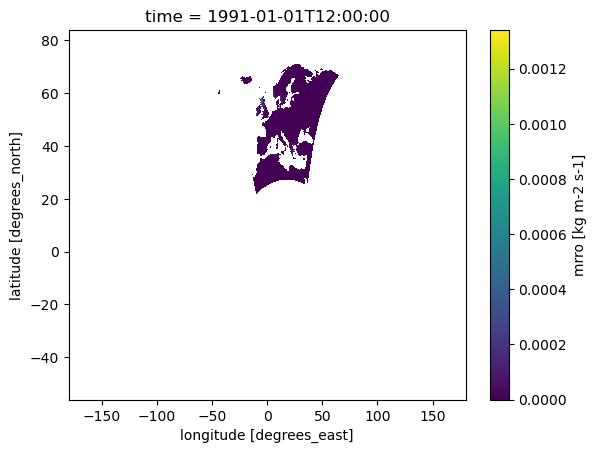

In [8]:
xr.open_dataset(block_file_regridded).isel(time=0).mrro.plot()

In [24]:
list((tmp_climate_data_dir / "temp" / "mrro" / "blocks").glob("*.nc"))

[PosixPath('/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/cordex_processed/MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp26/temp/mrro/blocks/mrro_masked_regridded_1991_2010.nc'),
 PosixPath('/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/cordex_processed/MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp26/temp/mrro/blocks/mrro_masked_regridded_2011_2030.nc'),
 PosixPath('/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/cordex_processed/MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp26/temp/mrro/blocks/mrro_masked_regridded_2031_2050.nc'),
 PosixPath('/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/cordex_processed/MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp26/temp/mrro/blocks/mrro_masked_regridded_2051_2070.nc'),
 PosixPath('/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/cordex_processed/MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp26/temp/mrro/blocks/mrro_masked_regridded_2071_2090.nc'),
 PosixPath('/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/cordex_processed/MOHC-H

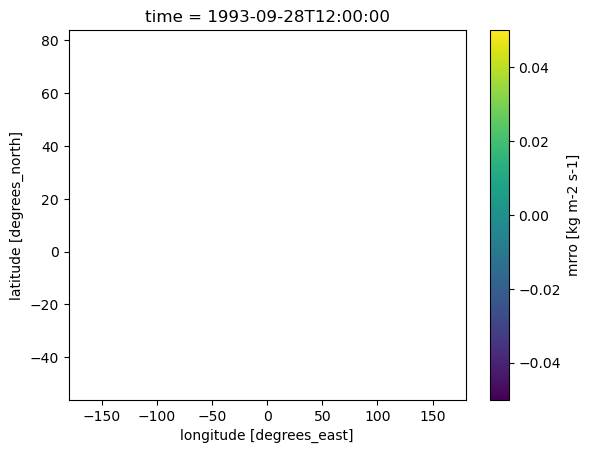

In [30]:
xr.open_dataset(tmp_climate_data_dir / "temp" / "mrro" / "blocks" / "mrro_masked_regridded_1991_2010.nc").isel(time=1000).mrro.plot()